# Pairs Trading with EUR/USD: handling the times when mean-reversion stops working

**What this notebook does**

1. Builds a pairs-trading strategy around the **Euro vs US Dollar** exchange rate.
2. Tests it on data the strategy has **never seen** (a fair test, called *out-of-sample*).
3. Compares **three versions** of the strategy, each handling "the relationship broke" differently:
   - **Strategy 1 – Classic:** fixed average and fixed spread width (breaks when the market changes).
   - **Strategy 2 – Rolling z-score:** average and width keep updating (the answer you gave in the interview).
   - **Strategy 3 – Rolling z-score + safety rules:** also *stops trading* when the relationship looks broken (the alternative approach).

---
## First question: can "Euro vs US Dollar" be a pair?

**Not directly.** EUR/USD is one number: how many dollars one euro costs. It is already a ratio of the two currencies, so there is nothing to put on the other side of the trade.

A pair needs **two instruments that normally move together**. The standard trick:

- Pairing **EUR/USD** with another currency quoted against the dollar, such as **GBP/USD**.

Both rates contain the same dollar, so the dollar mostly cancels out. What is left is a bet on **Euro vs Pound**:

log(EUR/USD) − log(GBP/USD) = log(EUR/GBP)

So the trade is: when the euro gets unusually expensive compared with the pound, sell EUR/USD and buy GBP/USD. Bet that the gap closes.

The notebook tests a few partner currencies (GBP, AUD, CHF) on the training period only and picks the one that moved together best. Only then do we test it on the unseen period.

**Step 1: Setup**

Importing libraries and setting up rules

I deliberately did not optimise these numbers. If I tune them until the backtest looks good, we are fitting noise, not finding a real edge.

In [2]:
!pip install -q yfinance statsmodels

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# ---------- Data periods ----------
START      = "2010-01-01"   # start of all data
TRAIN_END  = "2015-12-31"   # TRAINING period ends here (used to choose partner + hedge ratio + fixed mean/std)
TEST_START = "2016-01-01"   # TEST period (unseen) starts here. It includes Brexit, COVID, the 2022 euro-parity shock

# ---------- Which currencies to try as EUR/USD's partner ----------
PARTNERS = ["GBPUSD", "AUDUSD", "CHFUSD"]

# ---------- Trading rules ----------
ENTRY_Z  = 2.0    # enter when the spread is 2 standard widths away from its average
EXIT_Z   = 0.5    # exit when it is back within 0.5 of its average (take profit)
Z_WINDOW = 60     # rolling window (days) for the rolling z-score

# ---------- Safety rules (used only in Strategy 3) ----------
STOP_Z    = 3.5   # stop-loss: exit if the spread moves this far AGAINST us
MAX_HOLD  = 60    # time-stop: exit if a trade is still open after this many days
HL_WINDOW = 252   # look-back (about 1 trading year) for measuring the "health" of mean-reversion
HL_MAX    = 60    # trade only if the recent half-life is at most this many days

# ---------- Costs ----------
COST_BPS = 1.5    # cost per unit traded, in basis points (1 bp = 0.01%).

**Step 2: Downloading the data**

In [3]:
import yfinance as yf

tickers = ["EURUSD=X", "GBPUSD=X", "AUDUSD=X", "CHF=X"]
raw = yf.download(tickers, start=START, auto_adjust=True, progress=False)["Close"].dropna()

fx = pd.DataFrame({
    "EURUSD": raw["EURUSD=X"],
    "GBPUSD": raw["GBPUSD=X"],
    "AUDUSD": raw["AUDUSD=X"],
    "CHFUSD": 1 / raw["CHF=X"],     # flipped so it is "USD per CHF"
})

print(f"{fx.shape[0]} trading days, from {fx.index[0].date()} to {fx.index[-1].date()}")
display(fx.tail())

4373 trading days, from 2010-01-01 to 2026-10-23


,EURUSD,GBPUSD,AUDUSD,CHFUSD
Date,,,,
2026-10-19,1.122549,1.333565,0.697210,1.213961
2026-10-20,1.121579,1.330849,0.698280,1.209409
2026-10-21,1.122675,1.337327,0.700658,1.211196
2026-10-22,1.123469,1.339567,0.702930,1.213592
2026-10-23,1.119194,1.336684,0.702247,1.212827


**Step 3: Choosing the partner (using TRAINING data only)**

For each candidate partner I checked:

- **Hedge ratio β**: the slope from regressing log(EURUSD) on log(partner).
- **Cointegration p-value**: below 0.05 means the spread is likely to keep returning to its average. I have use statsmodels.coint, the correct version of this test. (Previously I used a plain ADF test on the residuals. That test is slightly too optimistic when the hedge ratio has been estimated from the same data.)
- **Half-life**: how fast the spread snaps back. Between a few days and a couple of months is practical.
- **Return correlation**: do their daily moves agree?

Only data up to TRAIN_END is used.

In [4]:
from statsmodels.tsa.stattools import coint

log_fx = np.log(fx)
train  = log_fx.loc[:TRAIN_END]


def half_life(spread):
    """
    Days for the spread to close half of its gap to the average.
    Idea: regress today's CHANGE in spread on yesterday's LEVEL.
    A negative slope means 'pulled back toward the average'. The more negative, the faster.
    """
    s   = spread.dropna()
    lag = s.shift(1).dropna()
    d   = (s - s.shift(1)).dropna()
    b   = np.polyfit(lag.values, d.values, 1)[0]    # slope
    if b >= 0 or b <= -1:
        return np.inf                               # no mean-reversion at all
    return -np.log(2) / np.log(1 + b)


rows = []
for partner in PARTNERS:
    y, x = train["EURUSD"], train[partner]
    beta, alpha = np.polyfit(x, y, 1)               # hedge ratio and intercept
    spr = y - beta * x - alpha
    rows.append({
        "partner": partner,
        "hedge_ratio_beta": beta,
        "coint_p_value": coint(y, x)[1],
        "half_life_days": half_life(spr),
        "daily_return_corr": train[["EURUSD", partner]].diff().corr().iloc[0, 1],
    })

scan = pd.DataFrame(rows).set_index("partner").sort_values("coint_p_value")
display(scan.round(4))

PARTNER = scan.index[0]        # best (lowest p-value) on TRAINING data.
print(f"\nSelected partner: {PARTNER}")
if scan.loc[PARTNER, "coint_p_value"] > 0.05:
    print("Note: even the best candidate is NOT cointegrated at the 5% level in the training period.")
    print("That is realistic for currencies. It is exactly why we need safety rules (Strategy 3).")

,hedge_ratio_beta,coint_p_value,half_life_days,daily_return_corr
partner,,,,
AUDUSD,0.5311,0.2268,87.2423,0.5481
GBPUSD,1.4129,0.6152,161.4960,0.6327
CHFUSD,0.4738,0.7827,234.5749,0.5307



Selected partner: AUDUSD
Note: even the best candidate is NOT cointegrated at the 5% level in the training period.
That is realistic for currencies. It is exactly why we need safety rules (Strategy 3).


In [5]:
# Fixing the hedge ratio and the training mean / std ONCE, from training data only.
BETA, ALPHA = np.polyfit(train[PARTNER], train["EURUSD"], 1)

# The spread for the whole period (training + test)
spread = log_fx["EURUSD"] - BETA * log_fx[PARTNER]

spread_train = spread.loc[:TRAIN_END]
MU_TRAIN, SD_TRAIN = spread_train.mean(), spread_train.std()

print(f"Hedge ratio (beta): {BETA:.3f}")
print(f"Training mean of spread: {MU_TRAIN:.4f}   Training std: {SD_TRAIN:.4f}")

Hedge ratio (beta): 0.531
Training mean of spread: 0.2948   Training std: 0.0491


**Step 4 :Visual check: does the pair really move together, and what happens after training?**

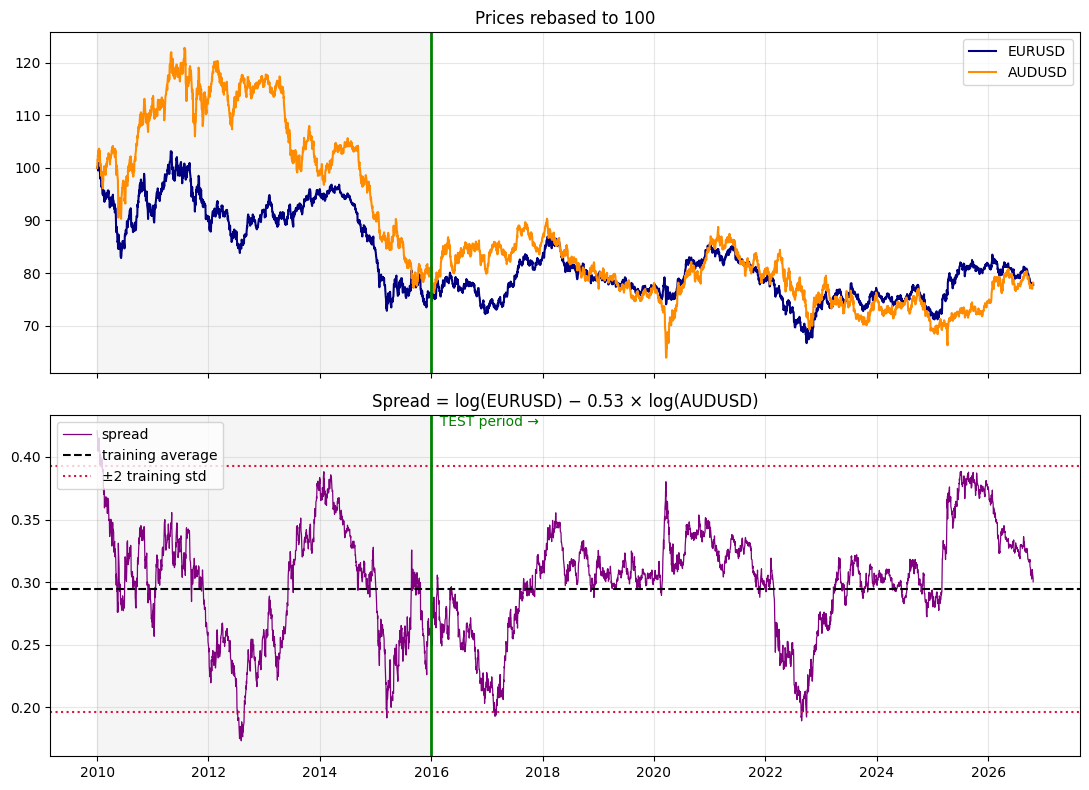

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

rebased = fx[["EURUSD", PARTNER]] / fx[["EURUSD", PARTNER]].iloc[0] * 100
axes[0].plot(rebased.index, rebased["EURUSD"], label="EURUSD", color="navy")
axes[0].plot(rebased.index, rebased[PARTNER], label=PARTNER, color="darkorange")
axes[0].set_title("Prices rebased to 100")
axes[0].legend()

axes[1].plot(spread.index, spread, color="purple", lw=0.9, label="spread")
axes[1].axhline(MU_TRAIN, color="black", ls="--", label="training average")
axes[1].axhline(MU_TRAIN + 2 * SD_TRAIN, color="crimson", ls=":", label="±2 training std")
axes[1].axhline(MU_TRAIN - 2 * SD_TRAIN, color="crimson", ls=":")
axes[1].set_title(f"Spread = log(EURUSD) − {BETA:.2f} × log({PARTNER})")
axes[1].legend(loc="upper left")

for ax in axes:
    ax.axvline(pd.Timestamp(TEST_START), color="green", lw=2)
    ax.axvspan(fx.index[0], pd.Timestamp(TEST_START), color="grey", alpha=0.08)
axes[1].text(pd.Timestamp(TEST_START), axes[1].get_ylim()[1], "  TEST period →", color="green", va="top")
plt.tight_layout(); plt.show()

- **Top chart:** both currencies rebased to 100 at the start. If they move together, the lines should look alike.
- **Bottom chart:** the spread. The black dashed line is the **training average** and the red lines are ±2 standard widths from training. We have to monitor what happens to the spread in the **test period** (right of the green line). If it drifts away and stays away, the old average is no longer valid. That is the "exception" we need to handle.

**Step 5: Creating The building blocks and trading rules(used by all three strategies)**

I wrote them once, then reused them, so the three strategies are compared fairly: only the "how we measure z" and "safety rules" change.

**A. make_positions: the trading rules.** It walks through the days one at a time and keeps track of whether we are:
- +1 = **long the spread** (buy EUR/USD, sell partner). Entered when z is very *low* (spread unusually cheap).
- -1 = **short the spread** (sell EUR/USD, buy partner). Entered when z is very *high*.
- 0 = flat (no trade).

Exit reasons:
- **target**: z came back near 0, so we take profit (all strategies).
- **stop_loss**: the spread kept moving against us (Strategy 3 only).
- **time_limit**: the trade is taking too long (Strategy 3 only).
- **regime_off**: the "health check" says mean-reversion is no longer working (Strategy 3 only).

After a stop-loss or time-limit we wait until z comes back inside the entry band before trading again, otherwise we would re-enter the same bad trade the very next day.

**B. backtes`: turns positions into profit and loss.**
- A signal seen at today's close is traded tomorrow, using shift(1). This avoids look-ahead bias.
- The two legs are sized so they match the spread: 1 unit of EUR/USD against β units of the partner (in money terms). This works because the spread is built from log prices.
- Each trade pays a small cost.

**C. performance: summary numbers.**

In [7]:
def make_positions(z, entry=ENTRY_Z, exit_=EXIT_Z, allowed=None, stop_z=None, max_hold=None):
    """
    Turn a z-score series into positions (+1 long spread, -1 short spread, 0 flat).

    z        : z-score per day
    allowed  : optional True/False per day. False = "do not trade, relationship looks broken"
    stop_z   : optional stop-loss level (in z units)
    max_hold : optional maximum days to stay in one trade
    Returns  : (positions Series, dict counting why trades were closed)
    """
    zv = z.values
    ok = (np.ones(len(z), dtype=bool) if allowed is None
          else allowed.reindex(z.index).fillna(False).values.astype(bool))

    pos = np.zeros(len(z))
    state, days_held, blocked = 0, 0, False
    exits = {"target": 0, "stop_loss": 0, "time_limit": 0, "regime_off": 0}

    for i, zi in enumerate(zv):
        if np.isnan(zi):                    # not enough history yet -> stay flat
            state = 0
            pos[i] = 0
            continue

        # After a forced exit, wait until the spread is back inside the entry band
        if blocked and abs(zi) < entry:
            blocked = False

        if state != 0:                      # ---- we are in a trade: should we leave? ----
            days_held += 1
            if stop_z is not None and state * zi <= -stop_z:     # moved too far against us
                state, blocked = 0, True
                exits["stop_loss"] += 1
            elif state * zi >= -exit_:                           # back near average: take profit
                state = 0
                exits["target"] += 1
            elif max_hold is not None and days_held >= max_hold: # trade is taking too long
                state, blocked = 0, True
                exits["time_limit"] += 1
            elif not ok[i]:                                      # health check failed
                state = 0
                exits["regime_off"] += 1

        elif ok[i] and not blocked:         # ---- flat: should we enter? ----
            if zi <= -entry:
                state, days_held = 1, 0     # spread unusually low -> buy it
            elif zi >= entry:
                state, days_held = -1, 0    # spread unusually high -> sell it

        pos[i] = state

    return pd.Series(pos, index=z.index), exits


def backtest(pos, prices, beta, cost_bps=COST_BPS):
    """
    pos    : +1 / 0 / -1 per day
    prices : DataFrame with columns "A" (EURUSD) and "B" (partner)
    Returns daily net returns of the strategy (after costs) and the position actually held each day.
    """
    rets  = prices.pct_change().fillna(0)
    gross = 1 + abs(beta)                               # so total exposure = 100% of capital while in a trade
    w = pd.DataFrame({"A": pos / gross, "B": -pos * beta / gross})
    w_held = w.shift(1).fillna(0)                       # trade on the NEXT day (no look-ahead)

    gross_ret = (w_held * rets).sum(axis=1)
    turnover  = w_held.diff().abs().sum(axis=1).fillna(0)
    net_ret   = gross_ret - turnover * cost_bps / 10_000
    return net_ret, pos.shift(1).fillna(0)


def performance(net_ret, pos_held):
    """Key performance numbers for one strategy."""
    equity = (1 + net_ret).cumprod()
    years  = (net_ret.index[-1] - net_ret.index[0]).days / 365.25
    vol    = net_ret.std() * np.sqrt(252)
    sharpe = net_ret.mean() / net_ret.std() * np.sqrt(252) if net_ret.std() > 0 else np.nan
    max_dd = (equity / equity.cummax() - 1).min()
    cagr   = equity.iloc[-1] ** (1 / years) - 1

    # Profit per individual trade (a trade = one continuous stretch with the same position)
    trade_id = (pos_held != pos_held.shift()).cumsum()
    in_trade = pos_held != 0
    trade_pnl = net_ret[in_trade].groupby(trade_id[in_trade]).sum()

    return pd.Series({
        "Total return":        equity.iloc[-1] - 1,
        "CAGR (yearly growth)": cagr,
        "Volatility (yearly)":  vol,
        "Sharpe ratio":         sharpe,
        "Max drawdown":         max_dd,
        "Calmar (CAGR / |MaxDD|)": cagr / abs(max_dd) if max_dd < 0 else np.nan,
        "Number of trades":     len(trade_pnl),
        "Win rate (per trade)": (trade_pnl > 0).mean() if len(trade_pnl) else np.nan,
        "Worst single trade":   trade_pnl.min() if len(trade_pnl) else np.nan,
        "Time in market":       in_trade.mean(),
    })


def plot_signals(z, pos, title):
    """Z-score with entry/exit lines. Orange shading = we hold a trade."""
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(z.index, z, lw=0.8, color="steelblue", label="z-score")
    ax.axhline(0, color="black", lw=0.8)
    for lvl in (ENTRY_Z, -ENTRY_Z): ax.axhline(lvl, color="crimson", ls="--", lw=1)
    for lvl in (EXIT_Z, -EXIT_Z):   ax.axhline(lvl, color="green", ls=":", lw=1)
    ax.fill_between(z.index, 0, 1, where=(pos != 0).values, transform=ax.get_xaxis_transform(),
                    color="orange", alpha=0.2, label="holding a trade")
    ax.set_ylim(max(z.min(), -8) - 0.5, min(z.max(), 8) + 0.5)
    ax.set_title(title); ax.legend(loc="upper left"); plt.tight_layout(); plt.show()


# ---- Preparing the test-period price table (columns renamed A = EURUSD, B = partner) ----
px = fx[["EURUSD", PARTNER]].copy()
px.columns = ["A", "B"]
px_test = px.loc[TEST_START:]
print(f"Test period: {px_test.index[0].date()} to {px_test.index[-1].date()}  ({len(px_test)} days)")

Test period: 2016-01-01 to 2026-10-23  (2813 days)


**Step 6 : Testing strategies**

**Strategy 1: Classic pairs trading (fixed average and width)**

The textbook version. We take the average and std from the training period and never update them.

z = (spread − training average) / training std

**Why it can fail:** if the market changes (e.g. a central bank shifts policy), the spread may settle at a new level. Our fixed ruler still says "z = +4, super expensive, sell!", and we keep betting against a spread that is not coming back. Losses pile up.

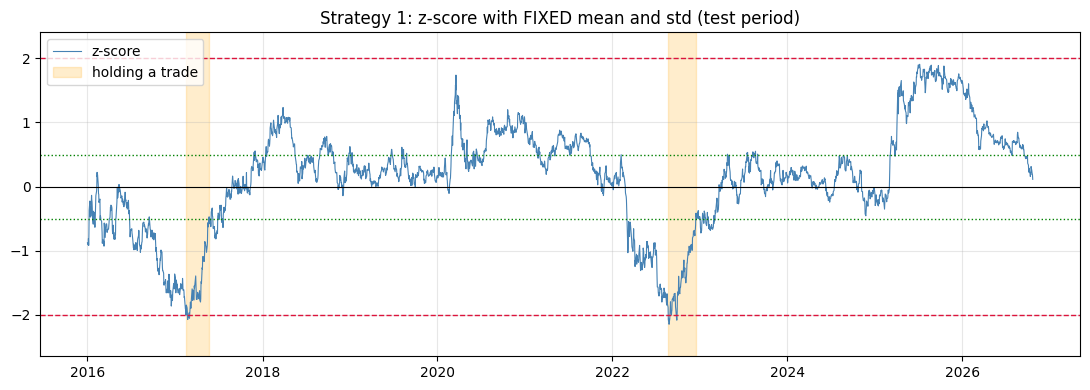

Why trades ended: {'target': 2, 'stop_loss': 0, 'time_limit': 0, 'regime_off': 0}


In [8]:
z1 = ((spread - MU_TRAIN) / SD_TRAIN).loc[TEST_START:]

pos1, exits1 = make_positions(z1)                        # no safety rules
net1, held1  = backtest(pos1, px_test, BETA)

plot_signals(z1, pos1, "Strategy 1: z-score with FIXED mean and std (test period)")
print("Why trades ended:", exits1)

**Strategy 2: Rolling z-score**

Instead of one fixed average, I used the last 60 days only:

z = (spread today − average of last 60 days) / std of last 60 days

**What it fixes:** if the spread moves to a new normal level, the 60-day average follows it within a couple of months.

**What it does NOT fix**:
1. It never tells us to stop trading. It simply keeps trading around a moving average, even if there is no mean-reversion at all.
2. During a steady trend, the rolling average chases the spread and z stays small, so the strategy sees no signal and misses it. When it finally does trade, it can be against the trend.
3. The window is a trade-off: too short and the average chases the spread, so real signals shrink; too long and it reacts slowly.
4. It cannot fix a wrong hedge ratio, which is still fixed from training.

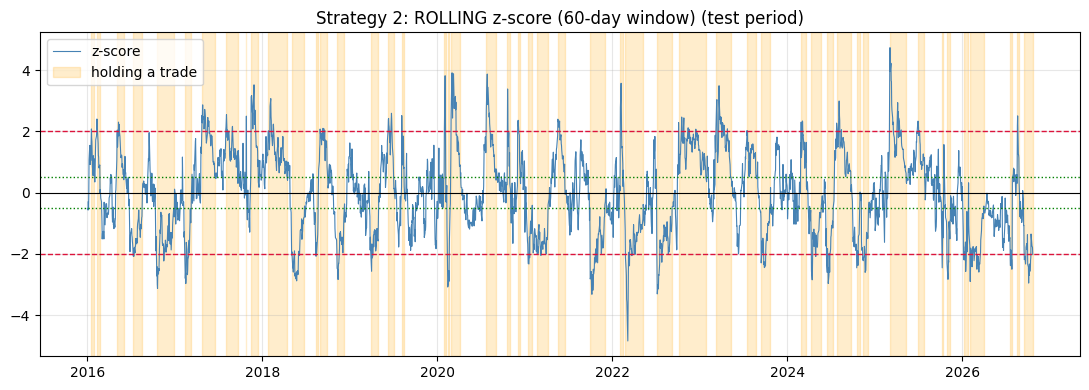

Why trades ended: {'target': 49, 'stop_loss': 0, 'time_limit': 0, 'regime_off': 0}


In [9]:
roll_mean = spread.rolling(Z_WINDOW).mean()
roll_std  = spread.rolling(Z_WINDOW).std()
z2_full   = (spread - roll_mean) / roll_std              # uses ONLY past days, so no look-ahead
z2        = z2_full.loc[TEST_START:]

pos2, exits2 = make_positions(z2)                        # still no safety rules
net2, held2  = backtest(pos2, px_test, BETA)

plot_signals(z2, pos2, f"Strategy 2: ROLLING z-score ({Z_WINDOW}-day window) (test period)")
print("Why trades ended:", exits2)

**Strategy 3: Rolling z-score + safety rules (the alternative approach)**

Rolling z-scores adapt the numbers. This strategy asks a different question: "Is mean-reversion working right now? If not, step aside."

It adds three simple safety rules on top of Strategy 2:

1. **Health check (regime filter).** Every day, look at the last ~1 year of the spread and measure its half-life. If the spread is currently snapping back quickly (half-life ≤ 60 days), trading is allowed. If it is drifting or trending (half-life very long or infinite), trading is blocked, and any open trade is closed.
2. **Stop-loss.** If z moves 3.5 widths against us, It accepts that it was wrong and exit.
3. **Time-stop.** If a trade has not worked after 60 days, exit. A trade that should close in a couple of weeks and has not is a warning sign.

It is a circuit breaker: we accept smaller profits in return for avoiding the big blow-ups.

**How the half-life health check works:** we regress daily change in spread on yesterday's spread level over a rolling 252-day window. If the slope is clearly negative, the spread is being pulled back. If it is near zero or positive, there is no pull-back: the spread just wanders or trends.

In [10]:
def rolling_half_life(spread, window=HL_WINDOW):
    """Half-life measured on a rolling window. Uses only past data. np.inf = no mean-reversion."""
    lag = spread.shift(1)
    d   = spread - lag
    slope = d.rolling(window).cov(lag) / lag.rolling(window).var()   # same slope as in half_life(), but rolling
    hl = pd.Series(np.inf, index=spread.index)
    good = (slope < 0) & (slope > -1)
    hl[good] = -np.log(2) / np.log1p(slope[good])
    hl[slope.isna()] = np.nan                                         # not enough history
    return hl

hl_roll = rolling_half_life(spread)
trading_allowed = (hl_roll >= 1) & (hl_roll <= HL_MAX)               # the health check (True = OK to trade)
allowed_test    = trading_allowed.loc[TEST_START:]

pos3, exits3 = make_positions(z2, allowed=allowed_test, stop_z=STOP_Z, max_hold=MAX_HOLD)
net3, held3  = backtest(pos3, px_test, BETA)

print("Why trades ended:", exits3)
print(f"Days when trading was allowed by the health check: {allowed_test.mean():.0%}")

Why trades ended: {'target': 30, 'stop_loss': 5, 'time_limit': 0, 'regime_off': 3}
Days when trading was allowed by the health check: 71%


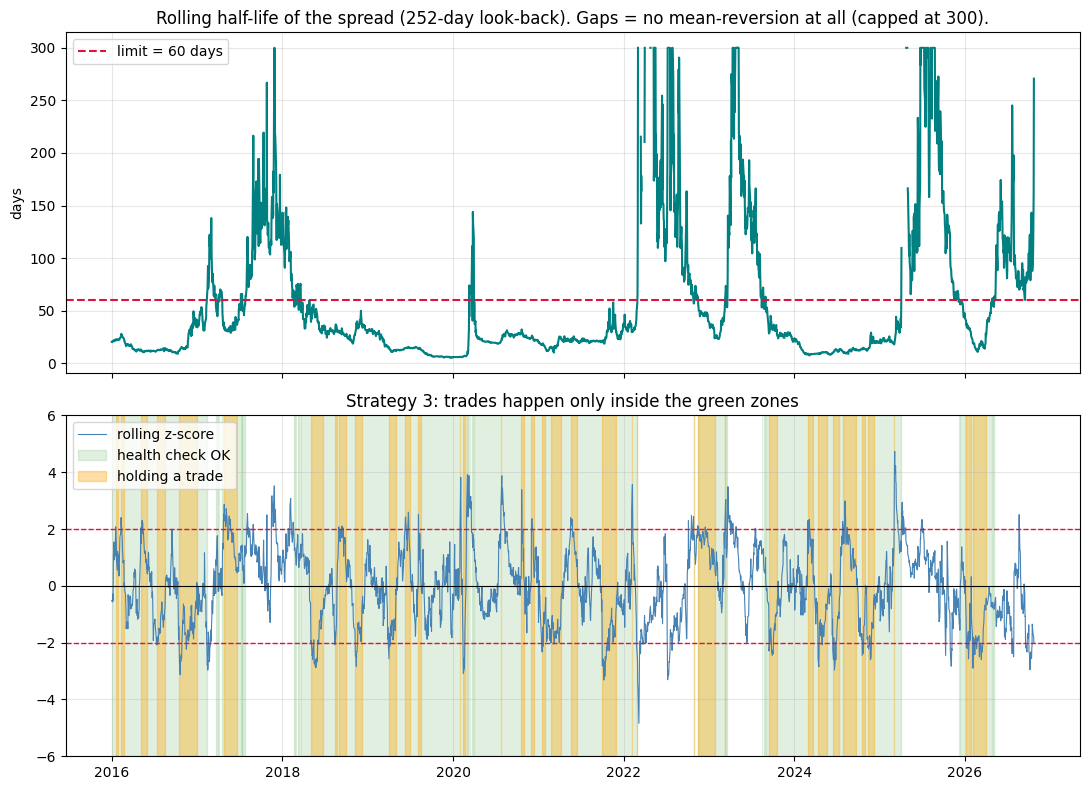

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

hl_plot = hl_roll.loc[TEST_START:].replace(np.inf, np.nan).clip(upper=300)
axes[0].plot(hl_plot.index, hl_plot, color="teal")
axes[0].axhline(HL_MAX, color="crimson", ls="--", label=f"limit = {HL_MAX} days")
axes[0].set_title(f"Rolling half-life of the spread ({HL_WINDOW}-day look-back). Gaps = no mean-reversion at all (capped at 300).")
axes[0].set_ylabel("days"); axes[0].legend()

axes[1].plot(z2.index, z2, lw=0.8, color="steelblue", label="rolling z-score")
for lvl in (ENTRY_Z, -ENTRY_Z): axes[1].axhline(lvl, color="crimson", ls="--", lw=1)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].fill_between(z2.index, 0, 1, where=allowed_test.values, transform=axes[1].get_xaxis_transform(),
                     color="green", alpha=0.12, label="health check OK")
axes[1].fill_between(z2.index, 0, 1, where=(pos3 != 0).values, transform=axes[1].get_xaxis_transform(),
                     color="orange", alpha=0.35, label="holding a trade")
axes[1].set_ylim(-6, 6)
axes[1].set_title("Strategy 3: trades happen only inside the green zones")
axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

**Visual: the check**

- **Top:** the rolling half-life (days). The red line is our limit. Above it the pair is "too slow / not mean-reverting".
- **Bottom:** the z-score with **green shading when the health check says "OK to trade"** and orange shading when a trade is actually open. In unshaded (white) periods the strategy deliberately stays out.

**Step 7: Comparing the three strategies**

- **Sharpe ratio** (return for the risk taken) and **Max drawdown** (worst fall) matter more than raw return. The strategies take different amounts of risk.
- **Number of trades** and **Worst single trade**: the safety rules should cut the worst single trade.
- **Yearly returns:** look for the years where Strategy 1 or 2 lose heavily. Those are likely the "exception" periods when the pair stopped mean-reverting.

In [12]:
results = pd.DataFrame({
    "1. Fixed z-score":            performance(net1, held1),
    "2. Rolling z-score":          performance(net2, held2),
    "3. Rolling z + safety rules": performance(net3, held3),
})

# Pretty formatting
pct_rows = ["Total return", "CAGR (yearly growth)", "Volatility (yearly)", "Max drawdown",
            "Win rate (per trade)", "Worst single trade", "Time in market"]
pretty = results.copy().astype(object)
for r in results.index:
    for c in results.columns:
        v = results.loc[r, c]
        pretty.loc[r, c] = (f"{v:.1%}" if r in pct_rows else
                            f"{v:.0f}" if r == "Number of trades" else f"{v:.2f}")
display(pretty)

,1. Fixed z-score,2. Rolling z-score,3. Rolling z + safety rules
Total return,10.7%,-3.1%,2.3%
CAGR (yearly growth),0.9%,-0.3%,0.2%
Volatility (yearly),1.1%,2.8%,1.8%
Sharpe ratio,0.84,-0.09,0.12
Max drawdown,-1.3%,-10.6%,-4.9%
Calmar (CAGR / |MaxDD|),0.71,-0.03,0.04
Number of trades,2,50,38
Win rate (per trade),100.0%,66.0%,60.5%
Worst single trade,4.9%,-2.8%,-1.5%
Time in market,5.4%,43.4%,25.2%


**Step 8: Visualizing results**

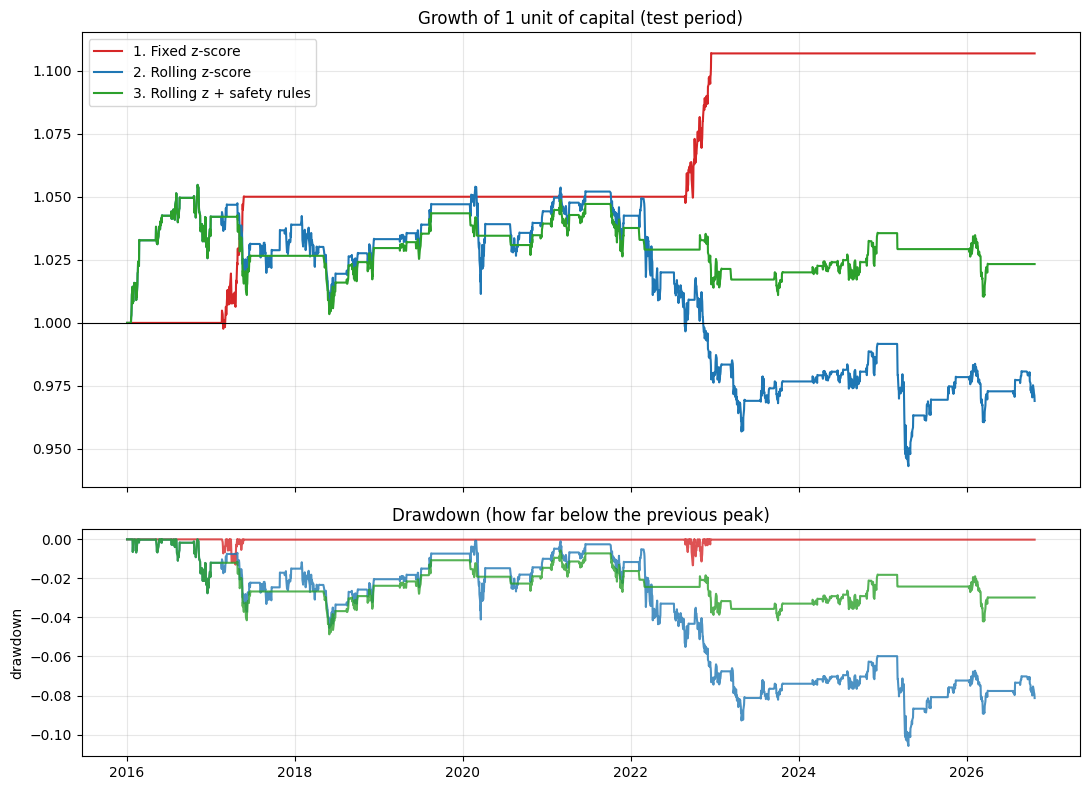

In [13]:
strategies = {"1. Fixed z-score": (net1, "tab:red"),
              "2. Rolling z-score": (net2, "tab:blue"),
              "3. Rolling z + safety rules": (net3, "tab:green")}

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for name, (net, colour) in strategies.items():
    equity = (1 + net).cumprod()
    axes[0].plot(equity.index, equity, label=name, color=colour)
    axes[1].plot(equity.index, equity / equity.cummax() - 1, color=colour, alpha=0.8)
axes[0].axhline(1, color="black", lw=0.8)
axes[0].set_title("Growth of 1 unit of capital (test period)"); axes[0].legend()
axes[1].set_title("Drawdown (how far below the previous peak)"); axes[1].set_ylabel("drawdown")
plt.tight_layout(); plt.show()

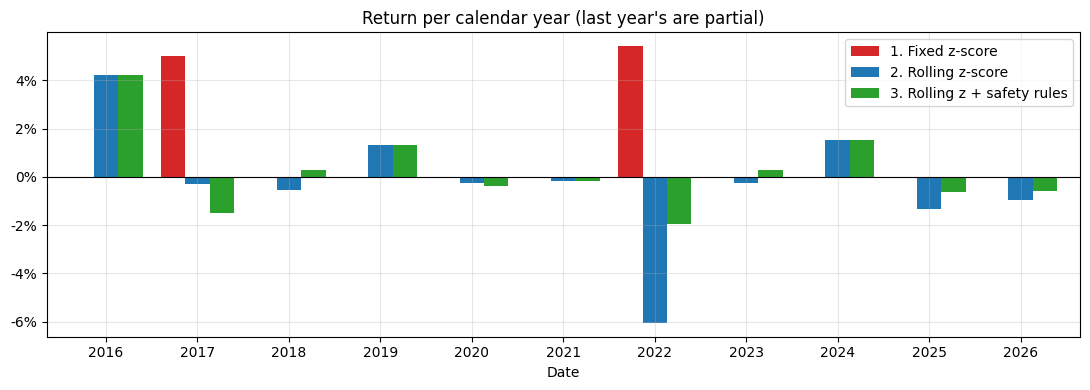

In [14]:
# Return per calendar year: shows WHICH years each strategy struggled
yearly = pd.DataFrame({name: net.groupby(net.index.year).apply(lambda r: (1 + r).prod() - 1)
                       for name, (net, _) in strategies.items()})

ax = yearly.plot(kind="bar", figsize=(11, 4), color=[c for _, c in strategies.values()], width=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Return per calendar year (last year's are partial)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Step 9 : Checking frequency of safety rules**

In [15]:
# Why did trades end? (How often did the safety rules act?)
exit_table = pd.DataFrame({"1. Fixed z-score": exits1, "2. Rolling z-score": exits2, "3. Rolling z + safety rules": exits3})
display(exit_table)

,1. Fixed z-score,2. Rolling z-score,3. Rolling z + safety rules
target,2,49,30
stop_loss,0,0,5
time_limit,0,0,0
regime_off,0,0,3


**Step 10: Conclusion from the strategy**


- Pairs trading rests on the spread being mean-reverting, and that can stop being true, for example after a central-bank shift. I handle it at three levels.
- **First**, I only traded pairs that pass a cointegration test on *training* data and I tested on unseen data.
- **Second**, I used a rolling z-score so the average and width follow the market, but I know that only adapts the numbers; it never tells me to stop.
- **Third**, I added a circuit breaker: a rolling half-life health check that blocks trading when mean-reversion is not visible, a stop-loss at a larger z-score, and a time-stop for trades that take too long.
- Entry is at |z| ≥ 2, take profit at |z| ≤ 0.5, stop-loss at 3.5. The levels are set from theory and not tuned to the backtest."

**Limitations :**

- **Daily Yahoo closes** are indicative prices, not tradable quotes, and **overnight interest (swap / carry)** on FX positions is not included.
- The hedge ratio is **fixed** from training. In real life we would re-estimate it periodically (or use a Kalman filter, which updates it continuously).
- Costs are a simple flat number. Real costs vary with market conditions and trade size.
